# Model tuning

Use the same five holdout partitions. Three-fold stratified **training-only** GridSearchCV tunes logistic regression, random forest, XGBoost and LightGBM. Every inner fold refits RFE-CART top-20 selection, Yeo-Johnson and scaling: using an already transformed outer-training matrix for inner tuning would leak selection information.

Validation chooses the tuned model family by ROC-AUC, then accuracy and lower FNR. The selected hyperparameters are used to fit the exported transformed 85% development dataset; its test set is evaluated once. Models are saved to **models/tuned/**. The test splits were also used by the fixed-model notebook, so these are reused internal evaluations, not fresh independent confirmation. Do not select tuning settings from test scores.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the project when launched from its root or notebooks directory.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "utils.py").is_file() and (p / "data/raw/dataset_gallstone").is_file())
sys.path.insert(0, str(ROOT))
from utils import (DEFAULT_SEEDS, DATASET_DIR, REPORT_METRICS, WORKFLOW_MODELS,
                   workflow_data, require_exports, prepare_holdout_exports,
                   load_pickle, continuous_columns, plot_evaluation)
sns.set_theme(style="whitegrid")
from utils import run_tuning_workflow


## 1. Tune within training, select on validation, refit and test

The finite grids and all fold-level scores are saved for review. Stacking remains a fixed benchmark in the other notebooks; this notebook tunes the four individual model families.


In [2]:
metrics, procedure_summary = run_tuning_workflow(selection="rfe")
display(metrics[["seed", "model", "evaluation", "accuracy", "roc_auc", "fnr"]])
display(procedure_summary)


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

Tuning seed 42: logistic


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning

...

/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

Tuning seed 123: logistic


/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:219: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights_xp + intercept_xp
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: divide by zero encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quyduong106/projects/.venv/lib/python3.13/site-packages/sklearn/linear_model/_linear_loss.py:356: RuntimeWarning: overflow encountered in matmul
  X_grad = X.T @ grad_pointwise
/Users/quydu

,seed,model,evaluation,accuracy,roc_auc,fnr
0,42,logistic,validation,0.666667,0.776042,0.250000
1,42,random_forest,validation,0.666667,0.743056,0.333333
2,42,xgboost,validation,0.666667,0.744792,0.291667
3,42,lightgbm,validation,0.666667,0.750000,0.333333
4,42,logistic,test,0.812500,0.873264,0.125000
5,7,logistic,validation,0.750000,0.852431,0.333333
6,7,random_forest,validation,0.687500,0.809028,0.333333
7,7,xgboost,validation,0.729167,0.789931,0.250000
8,7,lightgbm,validation,0.645833,0.786458,0.333333
9,7,logistic,test,0.770833,0.873264,0.166667


,mean,var,std
accuracy,0.812500,0.001085,0.032940
roc_auc,0.878125,0.000638,0.025260
fnr,0.125000,0.006076,0.077951
recall,0.875000,0.006076,0.077951
specificity,0.750000,0.004340,0.065881
precision,0.780037,0.001546,0.039314
f1,0.822759,0.001202,0.034677


## 2. Held-out evaluation of the tuning procedure


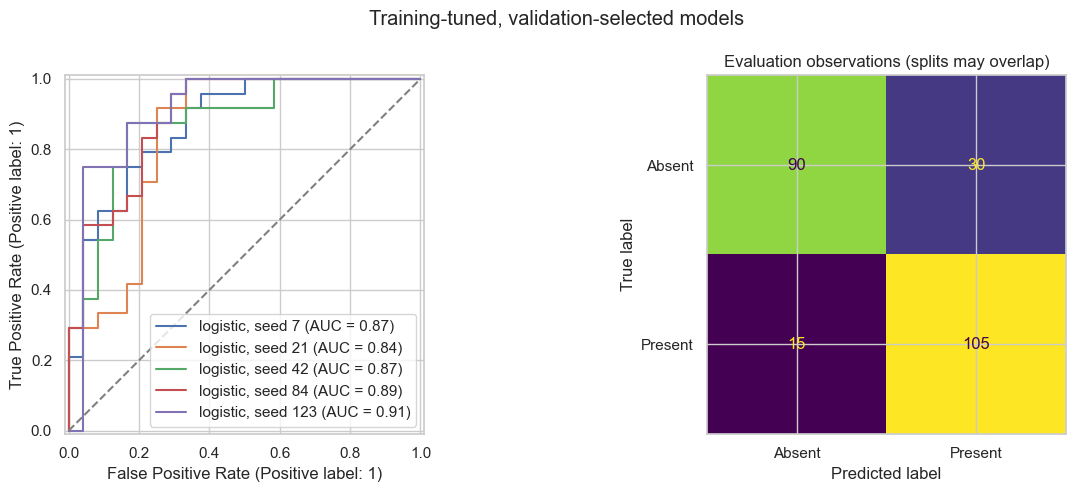

In [3]:
RESULTS = ROOT / "results" / "tuning"
predictions = pd.read_csv(RESULTS / "predictions.csv")
plot_evaluation(predictions.loc[predictions.evaluation == "test"],
                "Training-tuned, validation-selected models", RESULTS / "roc_confusion.png")
